# Retail Sales — Matplotlib: Complete Beginner Graphs + Data Analysis

**22 runnable graphs + 12 worked pandas analyses.** Shared reproducible 2,400-row synthetic retail transactions (2025). Each graph is named and explained with purpose, code reading guidance, interpretation, cautions and business action. No object-oriented plotting syntax is required. Run all cells in order.

**Note:** This is a simulated, realistic retail scenario—not actual company sales.

In [1]:
import numpy as np
import pandas as pd

rng = np.random.default_rng(42)
products = {
    'Electronics': [('Headphones', 2400, .68), ('Smartwatch', 5500, .70), ('Speaker', 3200, .66), ('Tablet', 18500, .78)],
    'Fashion': [('T-Shirt', 899, .50), ('Jeans', 1899, .53), ('Jacket', 3499, .56), ('Shoes', 2599, .58)],
    'Home & Kitchen': [('Cookware', 2799, .59), ('Lamp', 1299, .55), ('Mixer', 4499, .70), ('Bedsheet', 1599, .51)],
    'Beauty': [('Skincare Kit', 1499, .49), ('Perfume', 2999, .54), ('Hair Dryer', 2199, .61), ('Face Wash', 599, .46)]
}
records = []
for i in range(2400):
    month = int(rng.choice(np.arange(1, 13), p=[.065,.065,.075,.07,.075,.075,.08,.08,.09,.11,.12,.095]))
    day = int(rng.integers(1, pd.Period(f'2025-{month:02d}').days_in_month + 1))
    category = str(rng.choice(list(products), p=[.32,.29,.25,.14]))
    product, price, cost_ratio = products[category][int(rng.integers(0, 4))]
    region = str(rng.choice(['North','South','East','West'], p=[.25,.34,.18,.23]))
    channel = str(rng.choice(['Online','Retail Store','Marketplace'], p=[.47,.31,.22]))
    units = int(rng.choice([1,2,3,4,5,6], p=[.46,.27,.14,.07,.04,.02]))
    discount = float(rng.choice([0,.05,.10,.15,.20,.25], p=[.25,.24,.20,.16,.10,.05]))
    revenue = round(units * price * (1 - discount), 2)
    cost = round(units * price * cost_ratio, 2)
    profit = round(revenue - cost, 2)
    delivery = int(max(1, round(rng.normal(3.8 if channel != 'Retail Store' else 1.5, 1.7))))
    rating = float(np.clip(round(rng.normal(4.1 - .07 * max(delivery-4, 0), .55), 1), 1, 5))
    records.append([f'ORD-{i+1:05d}', f'2025-{month:02d}-{day:02d}', region, category, product,
                    str(rng.choice(['Consumer','Corporate','Small Business'], p=[.64,.23,.13])),
                    channel, units, price, discount, revenue, cost, profit,
                    round(100 * profit/revenue, 2), delivery, rating])
columns = ['Order_ID','Order_Date','Region','Category','Product','Customer_Segment','Sales_Channel',
           'Units','Unit_Price','Discount_Pct','Revenue','Cost','Profit','Margin_Pct','Delivery_Days','Customer_Rating']
df = pd.DataFrame(records, columns=columns).sort_values('Order_Date').reset_index(drop=True)
df['Order_Date'] = pd.to_datetime(df['Order_Date'])
df['Month_Num'] = df['Order_Date'].dt.month
df['Month'] = df['Order_Date'].dt.strftime('%b')
df['Quarter'] = 'Q' + df['Order_Date'].dt.quarter.astype(str)
month_order = ['Jan','Feb','Mar','Apr','May','Jun','Jul','Aug','Sep','Oct','Nov','Dec']
print('Dataset shape:', df.shape)
print('Total revenue: ₹{:,.0f} | Total profit: ₹{:,.0f}'.format(df['Revenue'].sum(), df['Profit'].sum()))
df.head()


Dataset shape: (2400, 19)
Total revenue: ₹18,118,715 | Total profit: ₹4,466,321


,Order_ID,Order_Date,Region,Category,Product,Customer_Segment,Sales_Channel,Units,Unit_Price,Discount_Pct,Revenue,Cost,Profit,Margin_Pct,Delivery_Days,Customer_Rating,Month_Num,Month,Quarter
0,ORD-00190,2025-01-01,North,Fashion,T-Shirt,Consumer,Marketplace,1,899,0.1,809.1,449.50,359.60,44.44,5,3.4,1,Jan,Q1
1,ORD-00326,2025-01-01,North,Home & Kitchen,Cookware,Small Business,Retail Store,1,2799,0.0,2799.0,1651.41,1147.59,41.00,1,4.1,1,Jan,Q1
2,ORD-00432,2025-01-01,West,Home & Kitchen,Mixer,Consumer,Online,4,4499,0.0,17996.0,12597.20,5398.80,30.00,6,4.6,1,Jan,Q1
3,ORD-00836,2025-01-01,East,Fashion,Jacket,Corporate,Marketplace,3,3499,0.1,9447.3,5878.32,3568.98,37.78,4,3.2,1,Jan,Q1
4,ORD-00972,2025-01-01,South,Electronics,Speaker,Consumer,Retail Store,1,3200,0.1,2880.0,2112.00,768.00,26.67,1,4.6,1,Jan,Q1


## How to read a business chart

**Business context:** You are a retail data analyst studying a fictional Indian retail business with 2,400 transactions in 2025. All values are generated examples, not observed real-world sales.

**Start with a question → choose a measure → group the data → plot → interpret → take action.** For example, “Which region is most profitable?” requires `groupby('Region')['Profit'].sum()`, not a count of records.

**Important measures:** `Revenue` is money received after discounts, `Cost` is estimated associated cost, `Profit = Revenue - Cost`, and `Margin_Pct = Profit / Revenue × 100` for each order. Overall business margin must be calculated as **total profit / total revenue**, not the simple mean of order margins.

**Graph-reading checklist:** (1) Identify the x and y variables and units. (2) Check whether the y-value is a sum, count, mean, or proportion. (3) Locate peaks, lows, exceptions and gaps. (4) Consider sample size, discounts and product mix. (5) Translate the pattern into a testable business action.

**Caution:** Correlation does not establish causation. A category with the highest sales is not automatically the most profitable. Charts from simulated data illustrate analysis techniques, not real market trends.


## Dataset overview and business questions

This sample mimics a multi-category Indian retailer selling through Online, Retail Store and Marketplace channels. **Revenue** is sales after discounts; **Profit = Revenue − Cost**. Values are in Indian rupees (₹).

- Orders: **2,400**; annual revenue: **₹18,118,715**; annual profit: **₹4,466,321**.
- Top category by revenue: **Electronics** (₹11,460,200).
- Highest-revenue month: **November** (₹2,543,583).
- Leading channel by revenue: **Online** (48.3% of total).

> Learning note: These findings describe the **generated practice dataset**, not an actual retailer. A graph shows associations and patterns; it does not prove causation.

In [2]:
import matplotlib.pyplot as plt
%matplotlib inline

## 01. Line chart — monthly revenue

**Purpose:** See month-to-month revenue movement.

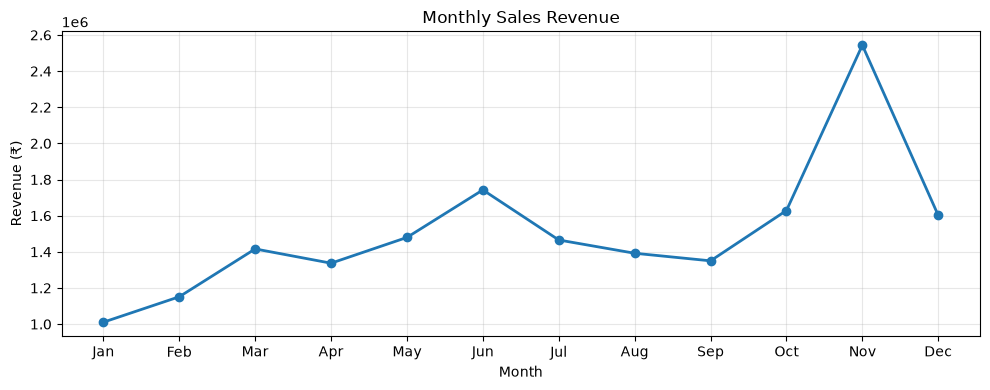

In [3]:
monthly = df.groupby('Month_Num')['Revenue'].sum()
plt.figure(figsize=(10, 4))
plt.plot(month_order, monthly.values, marker='o', linewidth=2)
plt.title('Monthly Sales Revenue')
plt.xlabel('Month'); plt.ylabel('Revenue (₹)')
plt.grid(alpha=0.3); plt.tight_layout(); plt.show()

**Outcome:** Revenue peaks in **November** at **₹2,543,583**.

**Suggested business decision:** Plan staffing and inventory around strong sales months.

**How to interpret:** Read the chart title and units first, then identify the strongest/weakest group or main trend. Check whether the chart uses total revenue, average per order, order counts, percentages or time; these cannot be compared interchangeably.

**Analysis practice:** Identify the highest and lowest values, calculate the gap or percentage difference using pandas, and explain whether the trend may reflect order volume, product prices, seasonality or mix.

**Limitations:** These are generated transactions. Do not infer causation or conclude that a pattern will hold in other years or real stores without more data.

**Manager question:** What should the retail team monitor next, and what additional data would validate the decision?

## 02. Vertical bar chart — revenue by category

**Purpose:** Compare total revenue across product categories.

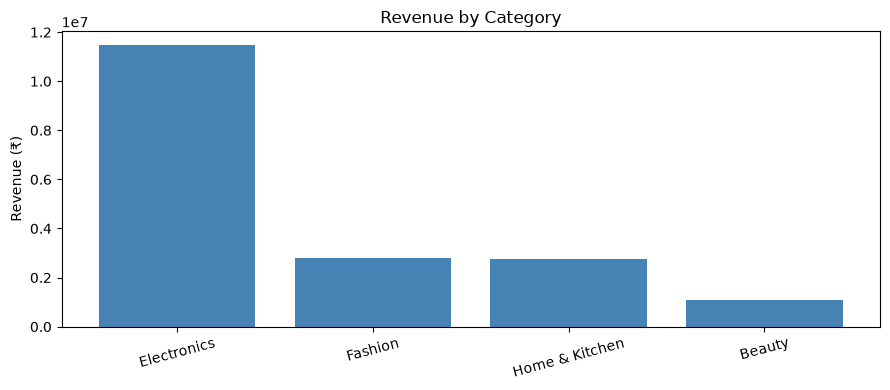

In [4]:
totals = df.groupby('Category')['Revenue'].sum().sort_values(ascending=False)
plt.figure(figsize=(9, 4))
plt.bar(totals.index, totals.values, color='steelblue')
plt.title('Revenue by Category'); plt.ylabel('Revenue (₹)')
plt.xticks(rotation=15); plt.tight_layout(); plt.show()

**Outcome:** **Electronics** earns the most revenue (₹11,460,200).

**Suggested business decision:** Prioritize inventory checks for top-revenue categories.

**How to interpret:** Read the chart title and units first, then identify the strongest/weakest group or main trend. Check whether the chart uses total revenue, average per order, order counts, percentages or time; these cannot be compared interchangeably.

**Analysis practice:** Identify the highest and lowest values, calculate the gap or percentage difference using pandas, and explain whether the trend may reflect order volume, product prices, seasonality or mix.

**Limitations:** These are generated transactions. Do not infer causation or conclude that a pattern will hold in other years or real stores without more data.

**Manager question:** What should the retail team monitor next, and what additional data would validate the decision?

## 03. Horizontal bar chart — profit by region

**Purpose:** Rank geographical regions by total profit.

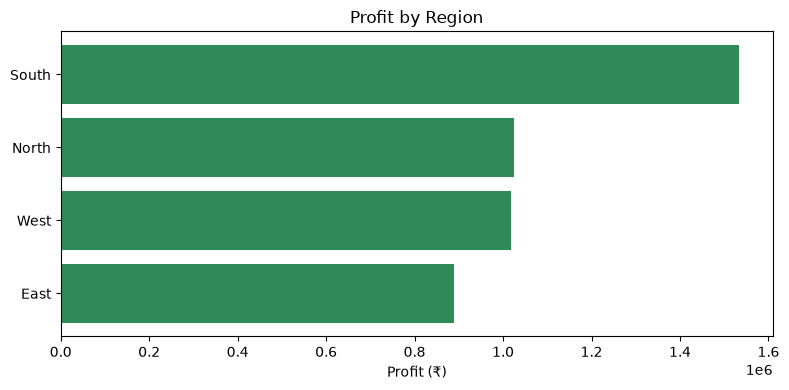

In [5]:
totals = df.groupby('Region')['Profit'].sum().sort_values()
plt.figure(figsize=(8, 4))
plt.barh(totals.index, totals.values, color='seagreen')
plt.title('Profit by Region'); plt.xlabel('Profit (₹)')
plt.tight_layout(); plt.show()

**Outcome:** **South** contributes the highest total profit (₹1,533,053).

**Suggested business decision:** Compare underperforming regions before changing budgets.

**How to interpret:** Read the chart title and units first, then identify the strongest/weakest group or main trend. Check whether the chart uses total revenue, average per order, order counts, percentages or time; these cannot be compared interchangeably.

**Analysis practice:** Identify the highest and lowest values, calculate the gap or percentage difference using pandas, and explain whether the trend may reflect order volume, product prices, seasonality or mix.

**Limitations:** These are generated transactions. Do not infer causation or conclude that a pattern will hold in other years or real stores without more data.

**Manager question:** What should the retail team monitor next, and what additional data would validate the decision?

## 04. Pie chart — channel revenue mix

**Purpose:** Show each sales channel’s share of total revenue.

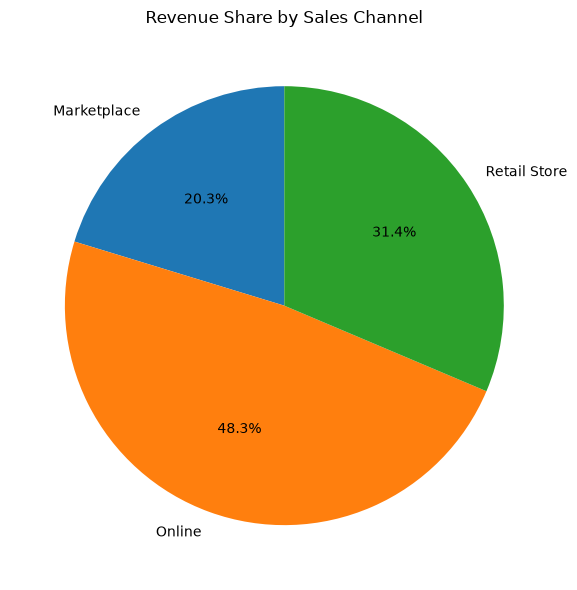

In [6]:
totals = df.groupby('Sales_Channel')['Revenue'].sum()
plt.figure(figsize=(6, 6))
plt.pie(totals.values, labels=totals.index, autopct='%1.1f%%', startangle=90)
plt.title('Revenue Share by Sales Channel')
plt.tight_layout(); plt.show()

**Outcome:** **Online** has the largest share (48.3%).

**Suggested business decision:** Consider channel-specific promotions and conversion analysis.

**How to interpret:** Read the chart title and units first, then identify the strongest/weakest group or main trend. Check whether the chart uses total revenue, average per order, order counts, percentages or time; these cannot be compared interchangeably.

**Analysis practice:** Identify the highest and lowest values, calculate the gap or percentage difference using pandas, and explain whether the trend may reflect order volume, product prices, seasonality or mix.

**Limitations:** These are generated transactions. Do not infer causation or conclude that a pattern will hold in other years or real stores without more data.

**Manager question:** What should the retail team monitor next, and what additional data would validate the decision?

## 05. Histogram — order revenue

**Purpose:** Examine the distribution of order values.

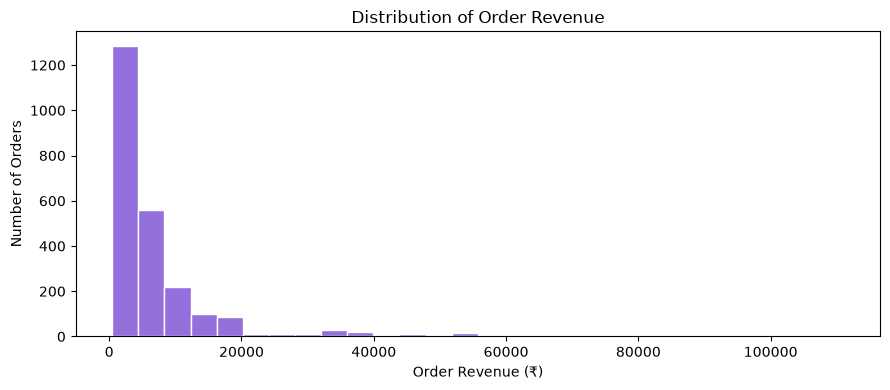

In [7]:
plt.figure(figsize=(9, 4))
plt.hist(df['Revenue'], bins=28, color='mediumpurple', edgecolor='white')
plt.title('Distribution of Order Revenue')
plt.xlabel('Order Revenue (₹)'); plt.ylabel('Number of Orders')
plt.tight_layout(); plt.show()

**Outcome:** Median order value is **₹3,897**, while the average is **₹7,549**.

**Suggested business decision:** Use median order value to benchmark typical purchases.

**How to interpret:** Read the chart title and units first, then identify the strongest/weakest group or main trend. Check whether the chart uses total revenue, average per order, order counts, percentages or time; these cannot be compared interchangeably.

**Analysis practice:** Identify the highest and lowest values, calculate the gap or percentage difference using pandas, and explain whether the trend may reflect order volume, product prices, seasonality or mix.

**Limitations:** These are generated transactions. Do not infer causation or conclude that a pattern will hold in other years or real stores without more data.

**Manager question:** What should the retail team monitor next, and what additional data would validate the decision?

## 06. Scatter plot — discount versus profit margin

**Purpose:** Check whether discount size is associated with profit margin.

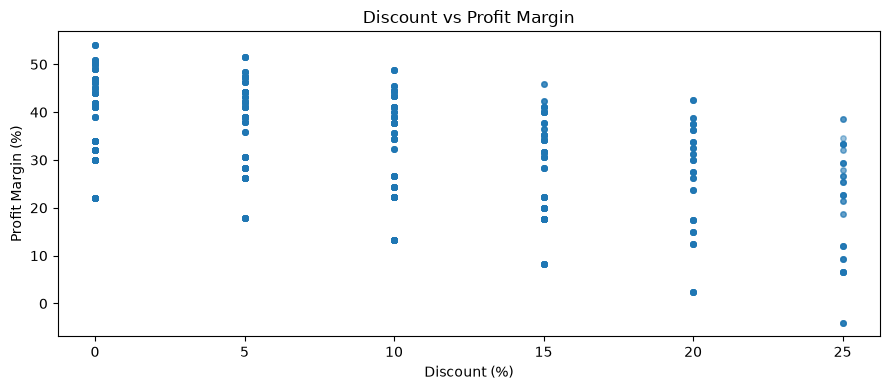

In [9]:
plt.figure(figsize=(9, 4))
plt.scatter(df['Discount_Pct'] * 100, df['Margin_Pct'], alpha=0.25, s=15)
plt.title('Discount vs Profit Margin')
plt.xlabel('Discount (%)'); plt.ylabel('Profit Margin (%)')
plt.tight_layout(); plt.show()

**Outcome:** Average margin is **33.1%**; larger discounts generally lower margins under the synthetic pricing formula.

**Suggested business decision:** Set discount guardrails after evaluating profitability.

**How to interpret:** Read the chart title and units first, then identify the strongest/weakest group or main trend. Check whether the chart uses total revenue, average per order, order counts, percentages or time; these cannot be compared interchangeably.

**Analysis practice:** Identify the highest and lowest values, calculate the gap or percentage difference using pandas, and explain whether the trend may reflect order volume, product prices, seasonality or mix.

**Limitations:** These are generated transactions. Do not infer causation or conclude that a pattern will hold in other years or real stores without more data.

**Manager question:** What should the retail team monitor next, and what additional data would validate the decision?

## 07. Box plot — delivery time by channel

**Purpose:** Compare delivery-time spread and outliers across channels.

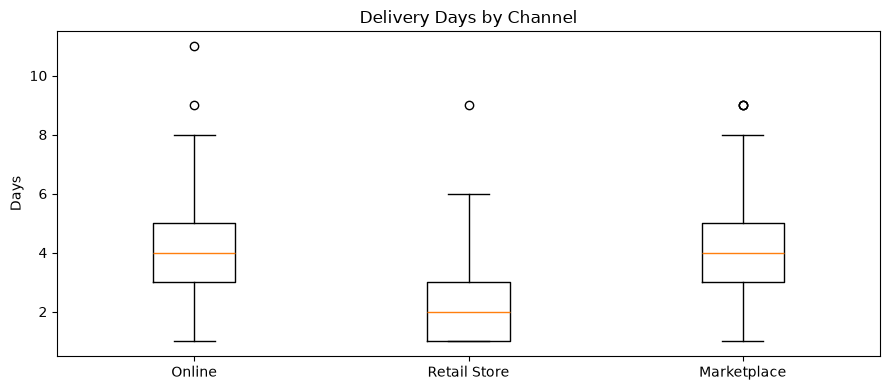

In [ ]:
groups = [df.loc[df['Sales_Channel'] == c, 'Delivery_Days'] for c in ['Online','Retail Store','Marketplace']]
plt.figure(figsize=(9, 4))
plt.boxplot(groups, tick_labels=['Online','Retail Store','Marketplace'])
plt.title('Delivery Days by Channel'); plt.ylabel('Days')
plt.tight_layout(); plt.show()

**Outcome:** Retail Store’s median delivery time is **2 days**, versus Online **4 days**.

**Suggested business decision:** Separate fulfilment benchmarks by channel.

**How to interpret:** Read the chart title and units first, then identify the strongest/weakest group or main trend. Check whether the chart uses total revenue, average per order, order counts, percentages or time; these cannot be compared interchangeably.

**Analysis practice:** Identify the highest and lowest values, calculate the gap or percentage difference using pandas, and explain whether the trend may reflect order volume, product prices, seasonality or mix.

**Limitations:** These are generated transactions. Do not infer causation or conclude that a pattern will hold in other years or real stores without more data.

**Manager question:** What should the retail team monitor next, and what additional data would validate the decision?

## 08. Stacked bar chart — category mix by channel

**Purpose:** See how revenue within each category is distributed across channels.

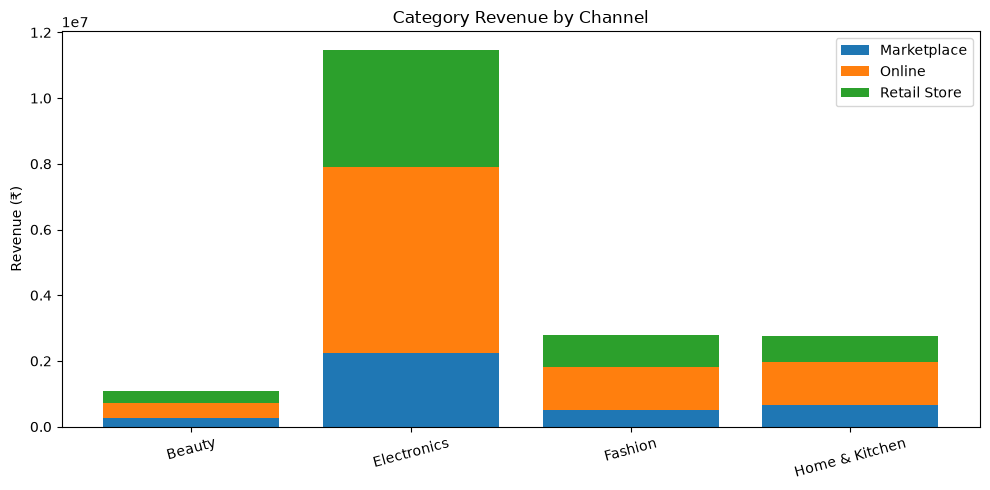

In [11]:
pivot = df.pivot_table(index='Category', columns='Sales_Channel', values='Revenue', aggfunc='sum', fill_value=0)
plt.figure(figsize=(10, 5))
bottom = np.zeros(len(pivot))
for channel in pivot.columns:
    plt.bar(pivot.index, pivot[channel], bottom=bottom, label=channel)
    bottom += pivot[channel].to_numpy()
plt.title('Category Revenue by Channel'); plt.ylabel('Revenue (₹)')
plt.xticks(rotation=15); plt.legend(); plt.tight_layout(); plt.show()

**Outcome:** Each bar represents category revenue, separated into channel contributions.

**Suggested business decision:** Look for category-channel combinations worth expanding.

**How to interpret:** Read the chart title and units first, then identify the strongest/weakest group or main trend. Check whether the chart uses total revenue, average per order, order counts, percentages or time; these cannot be compared interchangeably.

**Analysis practice:** Identify the highest and lowest values, calculate the gap or percentage difference using pandas, and explain whether the trend may reflect order volume, product prices, seasonality or mix.

**Limitations:** These are generated transactions. Do not infer causation or conclude that a pattern will hold in other years or real stores without more data.

**Manager question:** What should the retail team monitor next, and what additional data would validate the decision?

## 09. Area chart — monthly revenue

**Purpose:** Highlight volume and seasonal sales patterns.

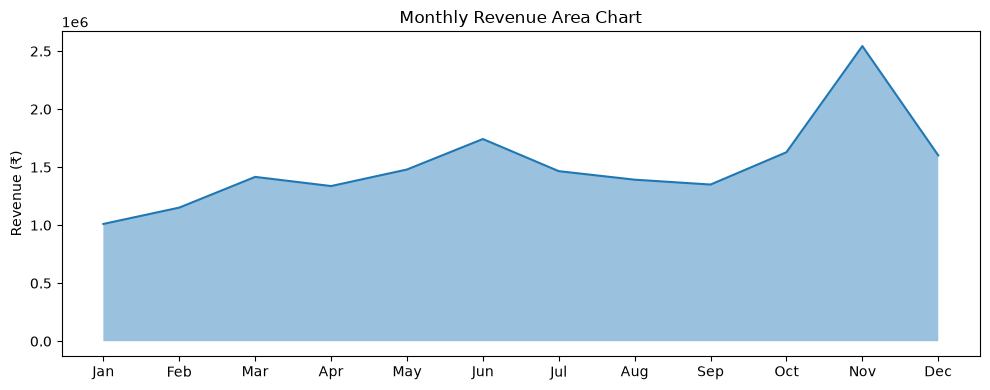

In [12]:
monthly = df.groupby('Month_Num')['Revenue'].sum()
plt.figure(figsize=(10, 4))
plt.fill_between(month_order, monthly.values, alpha=0.45)
plt.plot(month_order, monthly.values)
plt.title('Monthly Revenue Area Chart'); plt.ylabel('Revenue (₹)')
plt.tight_layout(); plt.show()

**Outcome:** The largest area peak occurs in **November**.

**Suggested business decision:** Use seasonal volume patterns in stock forecasting.

**How to interpret:** Read the chart title and units first, then identify the strongest/weakest group or main trend. Check whether the chart uses total revenue, average per order, order counts, percentages or time; these cannot be compared interchangeably.

**Analysis practice:** Identify the highest and lowest values, calculate the gap or percentage difference using pandas, and explain whether the trend may reflect order volume, product prices, seasonality or mix.

**Limitations:** These are generated transactions. Do not infer causation or conclude that a pattern will hold in other years or real stores without more data.

**Manager question:** What should the retail team monitor next, and what additional data would validate the decision?

## 10. Heatmap with imshow — month and category

**Purpose:** Spot high-revenue month-category combinations.

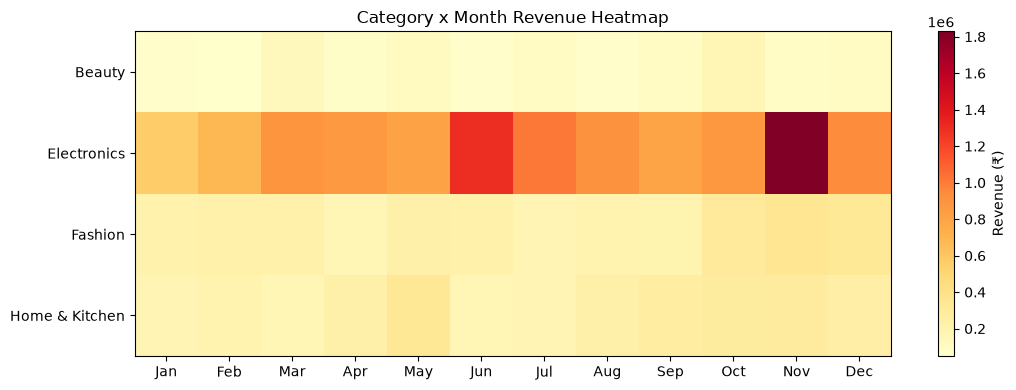

In [13]:
pivot = df.pivot_table(index='Category', columns='Month_Num', values='Revenue', aggfunc='sum', fill_value=0)
plt.figure(figsize=(11, 4))
plt.imshow(pivot.values, aspect='auto', cmap='YlOrRd')
plt.colorbar(label='Revenue (₹)')
plt.yticks(range(len(pivot.index)), pivot.index)
plt.xticks(range(12), month_order)
plt.title('Category x Month Revenue Heatmap')
plt.tight_layout(); plt.show()

**Outcome:** Darker cells indicate stronger revenue for that category and month.

**Suggested business decision:** Investigate seasonal bestsellers at category level.

**How to interpret:** Read the chart title and units first, then identify the strongest/weakest group or main trend. Check whether the chart uses total revenue, average per order, order counts, percentages or time; these cannot be compared interchangeably.

**Analysis practice:** Identify the highest and lowest values, calculate the gap or percentage difference using pandas, and explain whether the trend may reflect order volume, product prices, seasonality or mix.

**Limitations:** These are generated transactions. Do not infer causation or conclude that a pattern will hold in other years or real stores without more data.

**Manager question:** What should the retail team monitor next, and what additional data would validate the decision?

## 11. Grouped bar chart — quarterly revenue by region

**Purpose:** Compare multiple regions side by side in each quarter.

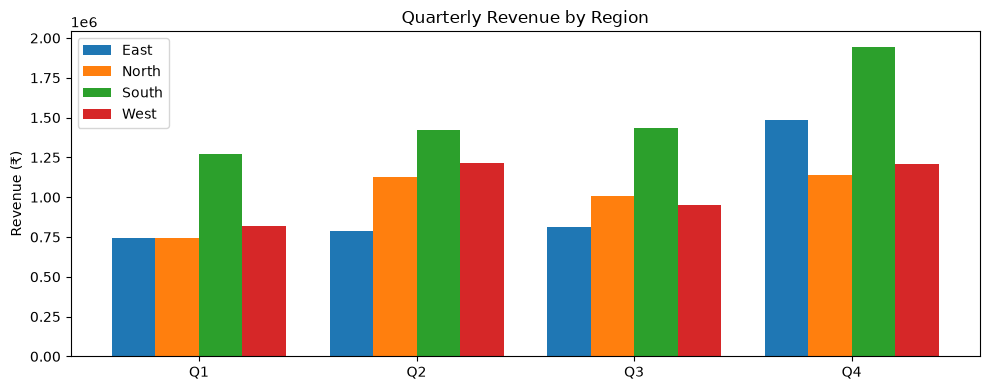

In [14]:
pivot = df.pivot_table(index='Quarter', columns='Region', values='Revenue', aggfunc='sum', fill_value=0).reindex(['Q1','Q2','Q3','Q4'])
x = np.arange(len(pivot)); width = 0.2
plt.figure(figsize=(10, 4))
for i, region in enumerate(pivot.columns):
    plt.bar(x + i * width, pivot[region], width, label=region)
plt.xticks(x + 1.5 * width, pivot.index)
plt.title('Quarterly Revenue by Region'); plt.ylabel('Revenue (₹)')
plt.legend(); plt.tight_layout(); plt.show()

**Outcome:** **Q4** is the highest-revenue quarter (₹5,773,955).

**Suggested business decision:** Compare quarterly targets across regions.

**How to interpret:** Read the chart title and units first, then identify the strongest/weakest group or main trend. Check whether the chart uses total revenue, average per order, order counts, percentages or time; these cannot be compared interchangeably.

**Analysis practice:** Identify the highest and lowest values, calculate the gap or percentage difference using pandas, and explain whether the trend may reflect order volume, product prices, seasonality or mix.

**Limitations:** These are generated transactions. Do not infer causation or conclude that a pattern will hold in other years or real stores without more data.

**Manager question:** What should the retail team monitor next, and what additional data would validate the decision?

## 12. Cumulative line chart — revenue growth

**Purpose:** Track total revenue accumulated through the year.

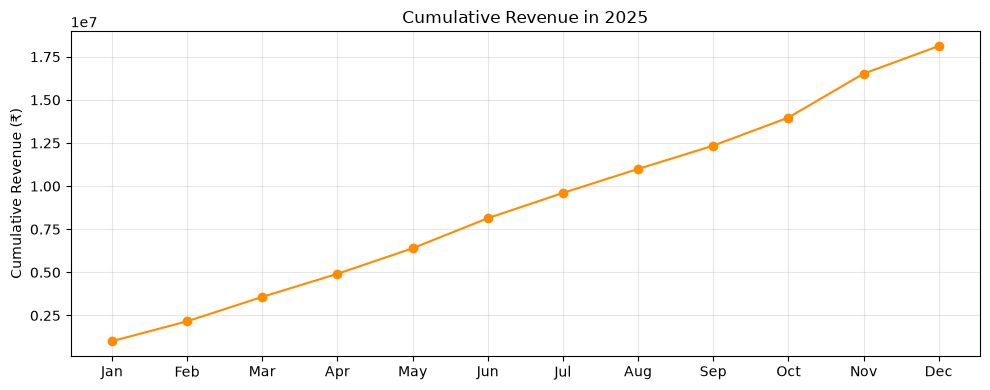

In [15]:
monthly = df.groupby('Month_Num')['Revenue'].sum().reindex(range(1, 13))
plt.figure(figsize=(10, 4))
plt.plot(month_order, monthly.cumsum(), marker='o', color='darkorange')
plt.title('Cumulative Revenue in 2025')
plt.ylabel('Cumulative Revenue (₹)'); plt.grid(alpha=.3)
plt.tight_layout(); plt.show()

**Outcome:** Cumulative revenue reaches **₹18,118,715** by December.

**Suggested business decision:** Track cumulative revenue against annual targets.

**How to interpret:** Read the chart title and units first, then identify the strongest/weakest group or main trend. Check whether the chart uses total revenue, average per order, order counts, percentages or time; these cannot be compared interchangeably.

**Analysis practice:** Identify the highest and lowest values, calculate the gap or percentage difference using pandas, and explain whether the trend may reflect order volume, product prices, seasonality or mix.

**Limitations:** These are generated transactions. Do not infer causation or conclude that a pattern will hold in other years or real stores without more data.

**Manager question:** What should the retail team monitor next, and what additional data would validate the decision?

## Part B — Additional basic and practical graphs

These ten charts add common beginner-friendly and industry-useful chart families. For each, learn when to use it, what the plotted variable represents, and which business action it might support.

### 13. Step chart — daily orders over a week

**Purpose:** Show discrete day-to-day order volumes, useful for staffing and warehouse scheduling.

**What to check before plotting:** Confirm the correct unit, grouping, and any data filtering. A sum measures business size, a mean measures typical value, and a count measures activity.

**Code walkthrough:** The pandas preparation creates the fields to plot. The next lines choose a chart, set a title and readable labels, then display it.

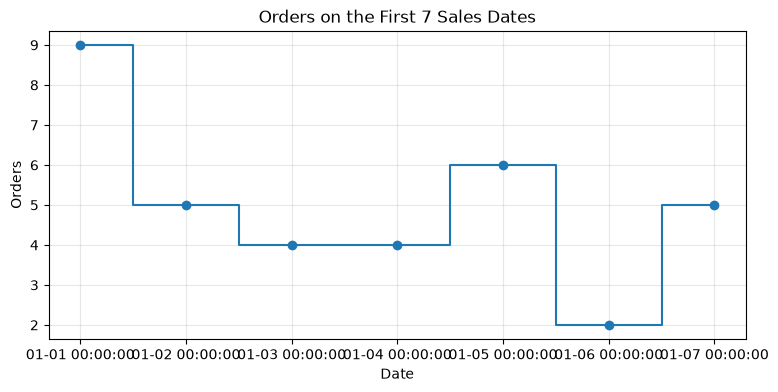

In [16]:
daily = df.groupby('Order_Date').size().head(7)
plt.figure(figsize=(9,4))
plt.step(range(1, len(daily)+1), daily.values, where='mid', marker='o')
plt.xticks(range(1, len(daily)+1), [str(x)[5:] for x in daily.index])
plt.xlabel('Date'); plt.ylabel('Orders'); plt.title('Orders on the First 7 Sales Dates')
plt.grid(alpha=.3); plt.show()

**Interpretation:** A step chart emphasizes discrete changes. Daily variation should be checked over more weeks before changing shifts.

**Practical business application:** Identify the top and bottom groups, compare performance over time or by sales channel, and check whether the findings warrant an inventory, logistics, pricing or marketing experiment.

**Limitations and common mistakes:** Observe scale, sample size and aggregation. An apparent association is not proof of cause. Use a comparison table to confirm exact values before reporting.

**Student task:** Write two sentences: one describing a visible pattern, and another recommending what you would investigate next.

### 14. Bar chart with error bars — delivery consistency

**Purpose:** Compare channel average delivery times and variation.

**What to check before plotting:** Confirm the correct unit, grouping, and any data filtering. A sum measures business size, a mean measures typical value, and a count measures activity.

**Code walkthrough:** The pandas preparation creates the fields to plot. The next lines choose a chart, set a title and readable labels, then display it.

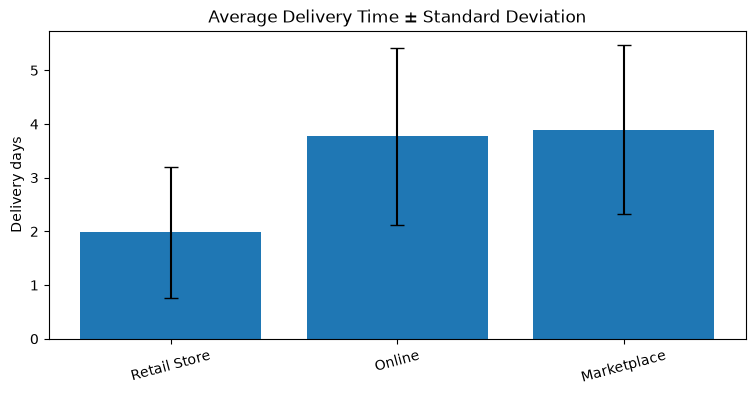

In [29]:
stats = df.groupby('Sales_Channel')['Delivery_Days'].agg(['mean','std']).sort_values('mean')
plt.figure(figsize=(9,4))
plt.bar(stats.index, stats['mean'], yerr=stats['std'], capsize=5)
plt.ylabel('Delivery days'); plt.title('Average Delivery Time ± Standard Deviation')
plt.xticks(rotation=15); plt.show()

**Interpretation:** The error bars show one standard deviation, NOT a confidence interval. Large spreads mean less predictable delivery.

**Practical business application:** Identify the top and bottom groups, compare performance over time or by sales channel, and check whether the findings warrant an inventory, logistics, pricing or marketing experiment.

**Limitations and common mistakes:** Observe scale, sample size and aggregation. An apparent association is not proof of cause. Use a comparison table to confirm exact values before reporting.

**Student task:** Write two sentences: one describing a visible pattern, and another recommending what you would investigate next.

### 15. Frequency polygon — order value distribution

**Purpose:** See the shape of a distribution by connecting histogram bin frequencies.

**What to check before plotting:** Confirm the correct unit, grouping, and any data filtering. A sum measures business size, a mean measures typical value, and a count measures activity.

**Code walkthrough:** The pandas preparation creates the fields to plot. The next lines choose a chart, set a title and readable labels, then display it.

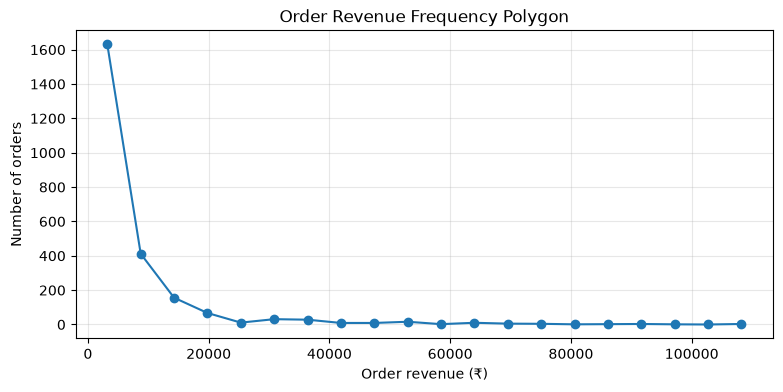

In [30]:
counts, edges = np.histogram(df['Revenue'], bins=20)
centers = (edges[:-1] + edges[1:]) / 2
plt.figure(figsize=(9,4)); plt.plot(centers, counts, marker='o')
plt.xlabel('Order revenue (₹)'); plt.ylabel('Number of orders'); plt.title('Order Revenue Frequency Polygon')
plt.grid(alpha=.3); plt.show()

**Interpretation:** A long right tail indicates a small number of high-value orders. The median is often more representative than the mean.

**Practical business application:** Identify the top and bottom groups, compare performance over time or by sales channel, and check whether the findings warrant an inventory, logistics, pricing or marketing experiment.

**Limitations and common mistakes:** Observe scale, sample size and aggregation. An apparent association is not proof of cause. Use a comparison table to confirm exact values before reporting.

**Student task:** Write two sentences: one describing a visible pattern, and another recommending what you would investigate next.

### 16. Stem plot — monthly profit

**Purpose:** Emphasize monthly totals as separate observations.

**What to check before plotting:** Confirm the correct unit, grouping, and any data filtering. A sum measures business size, a mean measures typical value, and a count measures activity.

**Code walkthrough:** The pandas preparation creates the fields to plot. The next lines choose a chart, set a title and readable labels, then display it.

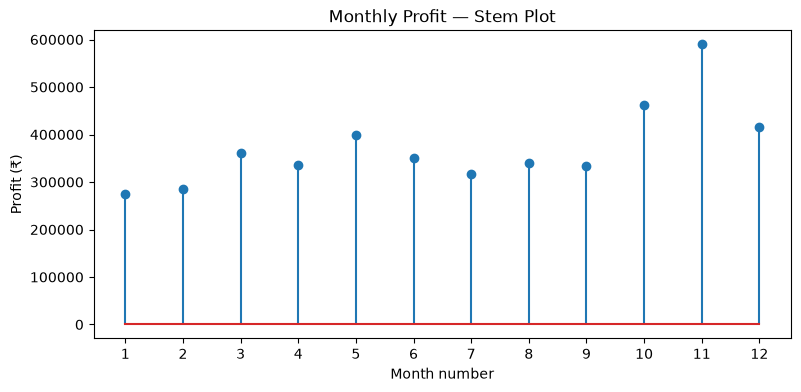

In [31]:
monthly_profit = df.groupby('Month_Num')['Profit'].sum()
plt.figure(figsize=(9,4)); plt.stem(monthly_profit.index, monthly_profit.values)
plt.xticks(range(1,13)); plt.xlabel('Month number'); plt.ylabel('Profit (₹)'); plt.title('Monthly Profit — Stem Plot'); plt.show()

**Interpretation:** Use stem plots for small discrete sequences. Compare high-profit months with high-revenue months.

**Practical business application:** Identify the top and bottom groups, compare performance over time or by sales channel, and check whether the findings warrant an inventory, logistics, pricing or marketing experiment.

**Limitations and common mistakes:** Observe scale, sample size and aggregation. An apparent association is not proof of cause. Use a comparison table to confirm exact values before reporting.

**Student task:** Write two sentences: one describing a visible pattern, and another recommending what you would investigate next.

### 17. Errorbar plot — monthly average order value

**Purpose:** Show average order value and its sampling uncertainty.

**What to check before plotting:** Confirm the correct unit, grouping, and any data filtering. A sum measures business size, a mean measures typical value, and a count measures activity.

**Code walkthrough:** The pandas preparation creates the fields to plot. The next lines choose a chart, set a title and readable labels, then display it.

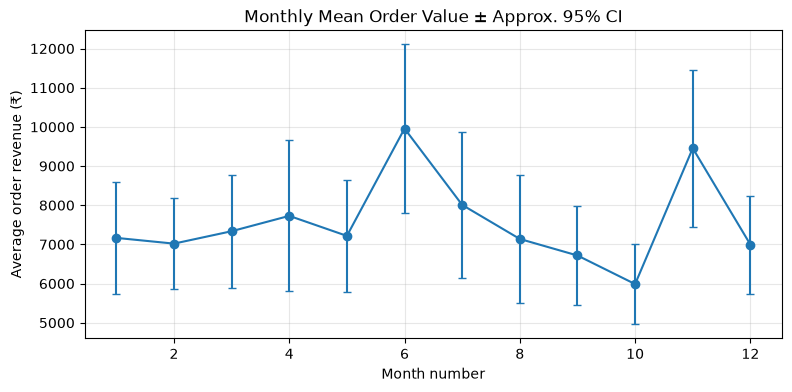

In [32]:
monthly_orders = df.groupby('Month_Num')['Revenue'].agg(['mean','sem'])
plt.figure(figsize=(9,4)); plt.errorbar(monthly_orders.index, monthly_orders['mean'], yerr=1.96*monthly_orders['sem'], fmt='o-', capsize=3)
plt.xlabel('Month number'); plt.ylabel('Average order revenue (₹)'); plt.title('Monthly Mean Order Value ± Approx. 95% CI'); plt.grid(alpha=.3); plt.show()

**Interpretation:** Approximate intervals are for the sample mean under usual assumptions; they are not prediction ranges for individual orders.

**Practical business application:** Identify the top and bottom groups, compare performance over time or by sales channel, and check whether the findings warrant an inventory, logistics, pricing or marketing experiment.

**Limitations and common mistakes:** Observe scale, sample size and aggregation. An apparent association is not proof of cause. Use a comparison table to confirm exact values before reporting.

**Student task:** Write two sentences: one describing a visible pattern, and another recommending what you would investigate next.

### 18. Hexbin plot — price and revenue density

**Purpose:** Reveal dense areas when thousands of scatter points overlap.

**What to check before plotting:** Confirm the correct unit, grouping, and any data filtering. A sum measures business size, a mean measures typical value, and a count measures activity.

**Code walkthrough:** The pandas preparation creates the fields to plot. The next lines choose a chart, set a title and readable labels, then display it.

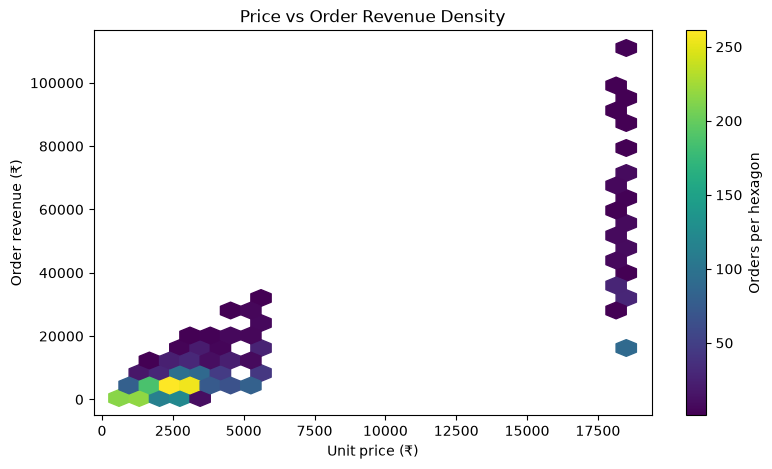

In [36]:
plt.figure(figsize=(9,5)); plt.hexbin(df['Unit_Price'], df['Revenue'], gridsize=25, mincnt=1, cmap='viridis')
plt.colorbar(label='Orders per hexagon'); plt.xlabel('Unit price (₹)'); plt.ylabel('Order revenue (₹)'); plt.title('Price vs Order Revenue Density'); plt.show()

**Interpretation:** Dense clusters show common price-and-basket combinations; revenue also depends on quantity and discounts.

**Practical business application:** Identify the top and bottom groups, compare performance over time or by sales channel, and check whether the findings warrant an inventory, logistics, pricing or marketing experiment.

**Limitations and common mistakes:** Observe scale, sample size and aggregation. An apparent association is not proof of cause. Use a comparison table to confirm exact values before reporting.

**Student task:** Write two sentences: one describing a visible pattern, and another recommending what you would investigate next.

### 19. Donut chart — order counts by channel

**Purpose:** Show the share of orders, not share of revenue.

**What to check before plotting:** Confirm the correct unit, grouping, and any data filtering. A sum measures business size, a mean measures typical value, and a count measures activity.

**Code walkthrough:** The pandas preparation creates the fields to plot. The next lines choose a chart, set a title and readable labels, then display it.

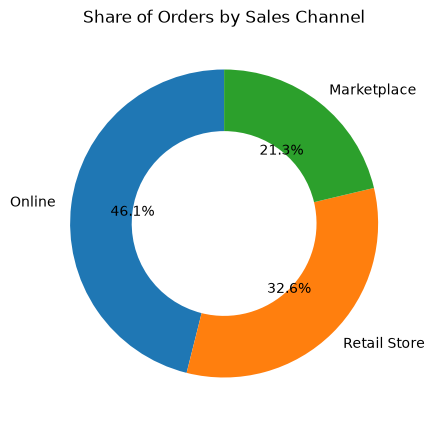

In [38]:
counts = df['Sales_Channel'].value_counts()
plt.figure(figsize=(7,5)); plt.pie(counts, labels=counts.index, autopct='%.1f%%', wedgeprops={'width':0.4}, startangle=90)
plt.title('Share of Orders by Sales Channel'); plt.show()

**Interpretation:** Order share and revenue share can differ because order sizes vary. Compare both before allocating marketing spend.

**Practical business application:** Identify the top and bottom groups, compare performance over time or by sales channel, and check whether the findings warrant an inventory, logistics, pricing or marketing experiment.

**Limitations and common mistakes:** Observe scale, sample size and aggregation. An apparent association is not proof of cause. Use a comparison table to confirm exact values before reporting.

**Student task:** Write two sentences: one describing a visible pattern, and another recommending what you would investigate next.

### 20. Pareto chart — product revenue

**Purpose:** Identify the products contributing most to revenue and their cumulative share.

**What to check before plotting:** Confirm the correct unit, grouping, and any data filtering. A sum measures business size, a mean measures typical value, and a count measures activity.

**Code walkthrough:** The pandas preparation creates the fields to plot. The next lines choose a chart, set a title and readable labels, then display it.

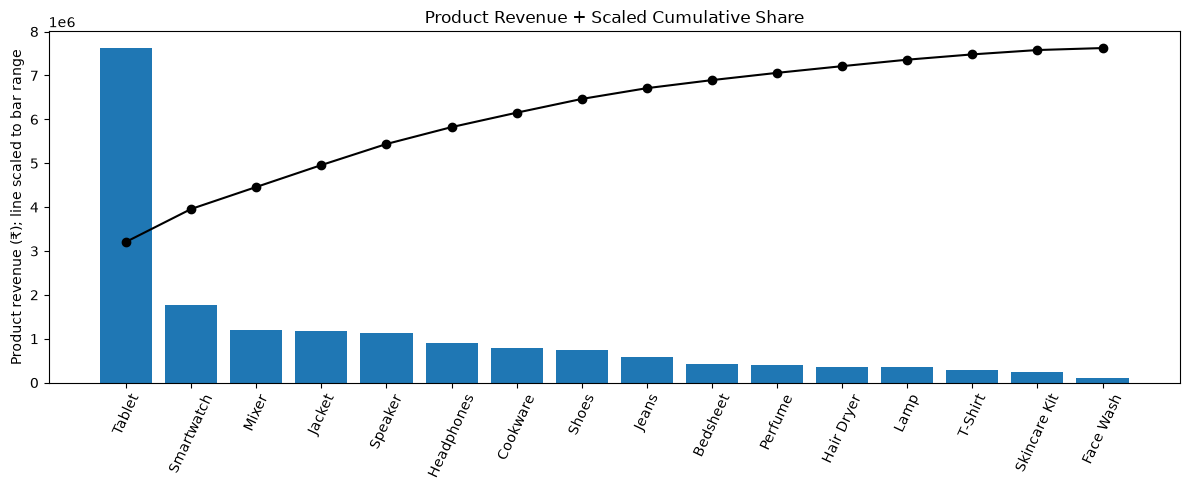

In [37]:
product_totals = df.groupby('Product')['Revenue'].sum().sort_values(ascending=False)
cumulative = product_totals.cumsum()/product_totals.sum()*100
plt.figure(figsize=(12,5)); plt.bar(product_totals.index, product_totals.values)
plt.plot(product_totals.index, cumulative.values*product_totals.max()/100, marker='o', color='black')
plt.xticks(rotation=65); plt.ylabel('Product revenue (₹); line scaled to bar range'); plt.title('Product Revenue + Scaled Cumulative Share'); plt.tight_layout(); plt.show()

**Interpretation:** The line is scaled for a single y-axis; use the table in the analysis section for exact cumulative percentages.

**Practical business application:** Identify the top and bottom groups, compare performance over time or by sales channel, and check whether the findings warrant an inventory, logistics, pricing or marketing experiment.

**Limitations and common mistakes:** Observe scale, sample size and aggregation. An apparent association is not proof of cause. Use a comparison table to confirm exact values before reporting.

**Student task:** Write two sentences: one describing a visible pattern, and another recommending what you would investigate next.

### 21. Filled line chart — monthly profit

**Purpose:** Compare monthly profit peaks with valleys using a filled baseline.

**What to check before plotting:** Confirm the correct unit, grouping, and any data filtering. A sum measures business size, a mean measures typical value, and a count measures activity.

**Code walkthrough:** The pandas preparation creates the fields to plot. The next lines choose a chart, set a title and readable labels, then display it.

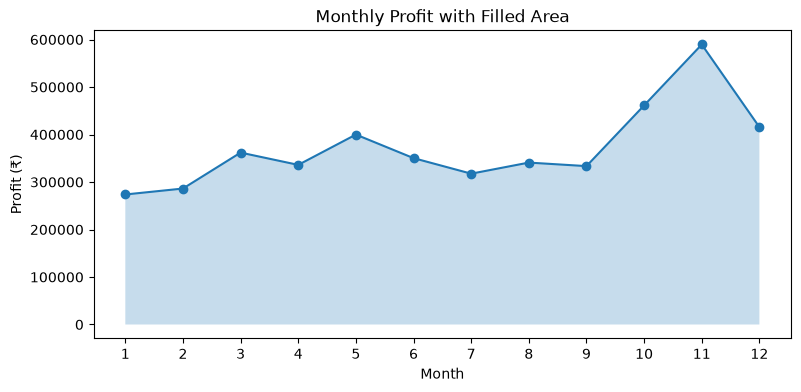

In [39]:
profits = df.groupby('Month_Num')['Profit'].sum()
plt.figure(figsize=(9,4)); plt.plot(profits.index, profits.values, marker='o')
plt.fill_between(profits.index, profits.values, alpha=.25)
plt.xticks(range(1,13)); plt.xlabel('Month'); plt.ylabel('Profit (₹)'); plt.title('Monthly Profit with Filled Area'); plt.show()

**Interpretation:** Compare profit patterns with sales patterns: a month with strong sales may still have weaker profitability.

**Practical business application:** Identify the top and bottom groups, compare performance over time or by sales channel, and check whether the findings warrant an inventory, logistics, pricing or marketing experiment.

**Limitations and common mistakes:** Observe scale, sample size and aggregation. An apparent association is not proof of cause. Use a comparison table to confirm exact values before reporting.

**Student task:** Write two sentences: one describing a visible pattern, and another recommending what you would investigate next.

### 22. Log-scale histogram — skewed order values

**Purpose:** Make a wide range of transaction sizes easier to examine.

**What to check before plotting:** Confirm the correct unit, grouping, and any data filtering. A sum measures business size, a mean measures typical value, and a count measures activity.

**Code walkthrough:** The pandas preparation creates the fields to plot. The next lines choose a chart, set a title and readable labels, then display it.

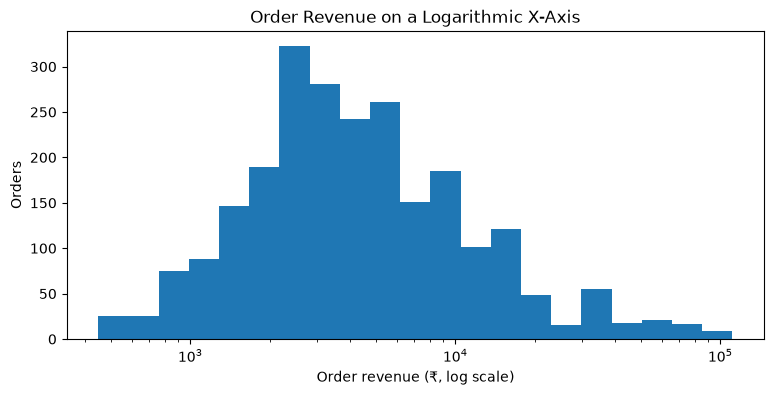

In [40]:
positive = df.loc[df['Revenue']>0,'Revenue']
plt.figure(figsize=(9,4)); plt.hist(positive, bins=np.logspace(np.log10(positive.min()),np.log10(positive.max()),22))
plt.xscale('log'); plt.xlabel('Order revenue (₹, log scale)'); plt.ylabel('Orders'); plt.title('Order Revenue on a Logarithmic X-Axis'); plt.show()

**Interpretation:** Equal horizontal distances represent multiplicative, not additive, increases. Never interpret a log axis as a linear axis.

**Practical business application:** Identify the top and bottom groups, compare performance over time or by sales channel, and check whether the findings warrant an inventory, logistics, pricing or marketing experiment.

**Limitations and common mistakes:** Observe scale, sample size and aggregation. An apparent association is not proof of cause. Use a comparison table to confirm exact values before reporting.

**Student task:** Write two sentences: one describing a visible pattern, and another recommending what you would investigate next.

## Part C — Hands-on retail data analysis with pandas

The next twelve worked examples go beyond plotting. They show how a business analyst checks raw data, calculates KPIs, groups records, examines exceptions, and turns results into recommendations. Run each cell and inspect the output.

### Analysis 01 — Data quality and structure

**Business question:** What does this analysis tell us about sales operations?

**Method:** Review the pandas operations in the code, then compare the output values.

In [44]:
# Review dataset size, sample rows, data types and missing values
print('Rows, columns:', df.shape)
display(df.head(5))
print('Duplicate order IDs:', df['Order_ID'].duplicated().sum())
print('Missing values by field:')
print(df.isna().sum().to_string())
print('Data types:')
print(df.dtypes.to_string())

Rows, columns: (2400, 20)


,Order_ID,Order_Date,Region,Category,Product,Customer_Segment,Sales_Channel,Units,Unit_Price,Discount_Pct,Revenue,Cost,Profit,Margin_Pct,Delivery_Days,Customer_Rating,Month_Num,Month,Quarter,Delivery_Group
0,ORD-00190,2025-01-01,North,Fashion,T-Shirt,Consumer,Marketplace,1,899,0.1,809.1,449.50,359.60,44.44,5,3.4,1,Jan,Q1,5–7 days
1,ORD-00326,2025-01-01,North,Home & Kitchen,Cookware,Small Business,Retail Store,1,2799,0.0,2799.0,1651.41,1147.59,41.00,1,4.1,1,Jan,Q1,0–2 days
2,ORD-00432,2025-01-01,West,Home & Kitchen,Mixer,Consumer,Online,4,4499,0.0,17996.0,12597.20,5398.80,30.00,6,4.6,1,Jan,Q1,5–7 days
3,ORD-00836,2025-01-01,East,Fashion,Jacket,Corporate,Marketplace,3,3499,0.1,9447.3,5878.32,3568.98,37.78,4,3.2,1,Jan,Q1,3–4 days
4,ORD-00972,2025-01-01,South,Electronics,Speaker,Consumer,Retail Store,1,3200,0.1,2880.0,2112.00,768.00,26.67,1,4.6,1,Jan,Q1,0–2 days


Duplicate order IDs: 0
Missing values by field:
Order_ID            0
Order_Date          0
Region              0
Category            0
Product             0
Customer_Segment    0
Sales_Channel       0
Units               0
Unit_Price          0
Discount_Pct        0
Revenue             0
Cost                0
Profit              0
Margin_Pct          0
Delivery_Days       0
Customer_Rating     0
Month_Num           0
Month               0
Quarter             0
Delivery_Group      0
Data types:
Order_ID                       str
Order_Date          datetime64[us]
Region                         str
Category                       str
Product                        str
Customer_Segment               str
Sales_Channel                  str
Units                        int64
Unit_Price                   int64
Discount_Pct               float64
Revenue                    float64
Cost                       float64
Profit                     float64
Margin_Pct                 float64
Delivery_D

**How to explain the outcome:** Check for duplicated IDs, invalid types and missing values before making a chart. A chart based on incomplete transactions can mislead management.

**Follow-up exercise:** Identify one concrete finding from the printed numbers and one additional field you would want from the real retail system.

### Analysis 02 — Core business KPIs

**Business question:** What does this analysis tell us about sales operations?

**Method:** Review the pandas operations in the code, then compare the output values.

In [42]:
total_revenue = df['Revenue'].sum()
total_profit = df['Profit'].sum()
orders = df['Order_ID'].nunique()
units_sold = df['Units'].sum()
kpis = pd.DataFrame({'Metric': ['Total revenue', 'Total profit', 'Total orders', 'Units sold', 'Average order value', 'Weighted profit margin (%)'], 'Value': [round(total_revenue,2), round(total_profit,2), orders, units_sold, round(total_revenue/orders,2), round(100*total_profit/total_revenue,2)]})
display(kpis)

,Metric,Value
0,Total revenue,18118715.05
1,Total profit,4466320.99
2,Total orders,2400.00
3,Units sold,4884.00
4,Average order value,7549.46
5,Weighted profit margin (%),24.65


**How to explain the outcome:** Sales value, profitability, units, order count and order value answer different management questions. Weighted margin uses total revenue as its denominator.

**Follow-up exercise:** Identify one concrete finding from the printed numbers and one additional field you would want from the real retail system.

### Analysis 03 — Category sales, margin and order volume

**Business question:** What does this analysis tell us about sales operations?

**Method:** Review the pandas operations in the code, then compare the output values.

In [ ]:
category_summary = df.groupby('Category').agg(Orders=('Order_ID','nunique'), Units=('Units','sum'), Revenue=('Revenue','sum'), Profit=('Profit','sum')).sort_values('Revenue', ascending=False)
category_summary['Margin_Pct'] = (100*category_summary['Profit']/category_summary['Revenue']).round(2)
category_summary['Avg_Order_Value'] = (category_summary['Revenue']/category_summary['Orders']).round(2)
display(category_summary.round(2))

**How to explain the outcome:** Compare revenue rank with margin and profit rank. Higher revenue may reflect premium-priced items, not superior efficiency.

**Follow-up exercise:** Identify one concrete finding from the printed numbers and one additional field you would want from the real retail system.

### Analysis 04 — Monthly growth and seasonality

**Business question:** What does this analysis tell us about sales operations?

**Method:** Review the pandas operations in the code, then compare the output values.

In [43]:
month_summary = df.groupby(['Month_Num','Month'], as_index=False).agg(Revenue=('Revenue','sum'), Profit=('Profit','sum'), Orders=('Order_ID','count')).sort_values('Month_Num')
month_summary['Growth_Pct'] = month_summary['Revenue'].pct_change().mul(100).round(2)
month_summary['Profit_Margin_Pct'] = (100*month_summary['Profit']/month_summary['Revenue']).round(2)
display(month_summary)

,Month_Num,Month,Revenue,Profit,Orders,Growth_Pct,Profit_Margin_Pct
0,1,Jan,1010508.90,273727.58,141,NaN,27.09
1,2,Feb,1151298.15,286242.25,164,13.93,24.86
2,3,Mar,1416004.65,361905.34,193,22.99,25.56
3,4,Apr,1337066.60,336050.02,173,-5.57,25.13
4,5,May,1479643.15,399865.90,205,10.66,27.02
5,6,Jun,1742538.65,350269.29,175,17.77,20.10
6,7,Jul,1465504.40,317539.76,183,-15.90,21.67
7,8,Aug,1392071.45,340879.43,195,-5.01,24.49
8,9,Sep,1350123.80,333456.74,201,-3.01,24.70
9,10,Oct,1628622.85,461278.79,272,20.63,28.32


**How to explain the outcome:** Month-on-month growth explains changes relative to the prior month. The first month has no prior-month comparison, so its growth is missing.

**Follow-up exercise:** Identify one concrete finding from the printed numbers and one additional field you would want from the real retail system.

### Analysis 05 — Region and channel performance

**Business question:** What does this analysis tell us about sales operations?

**Method:** Review the pandas operations in the code, then compare the output values.

In [ ]:
region_channel = df.pivot_table(index='Region', columns='Sales_Channel', values='Revenue', aggfunc='sum', fill_value=0)
region_channel['All_Channels'] = region_channel.sum(axis=1)
display(region_channel.round(2))
print('Top region by revenue:', region_channel['All_Channels'].idxmax())

**How to explain the outcome:** Use cross-tabulation to identify where a channel contributes most. Large revenue alone does not tell you the cost or margin of serving that market.

**Follow-up exercise:** Identify one concrete finding from the printed numbers and one additional field you would want from the real retail system.

### Analysis 06 — Top products and Pareto contribution

**Business question:** What does this analysis tell us about sales operations?

**Method:** Review the pandas operations in the code, then compare the output values.

In [ ]:
product_revenue = df.groupby('Product')['Revenue'].sum().sort_values(ascending=False)
product_share = pd.DataFrame({'Revenue': product_revenue})
product_share['Share_Pct'] = (product_share['Revenue']/product_share['Revenue'].sum()*100).round(2)
product_share['Cumulative_Share_Pct'] = product_share['Share_Pct'].cumsum().round(2)
display(product_share.head(10))

**How to explain the outcome:** Use the cumulative share to find whether a few products drive most revenue. The 80/20 rule is a hypothesis to test, not a guaranteed outcome.

**Follow-up exercise:** Identify one concrete finding from the printed numbers and one additional field you would want from the real retail system.

### Analysis 07 — Discount effectiveness and profitability

**Business question:** What does this analysis tell us about sales operations?

**Method:** Review the pandas operations in the code, then compare the output values.

In [ ]:
df['Discount_Band'] = pd.cut(df['Discount_Pct'], bins=[-0.001,0,0.05,0.10,0.15,1], labels=['0%','0–5%','5–10%','10–15%','15%+'])
discount_summary = df.groupby('Discount_Band', observed=True).agg(Orders=('Order_ID','count'), Revenue=('Revenue','sum'), Profit=('Profit','sum'))
discount_summary['Weighted_Margin_Pct'] = (100*discount_summary['Profit']/discount_summary['Revenue']).round(2)
display(discount_summary.round(2))

**How to explain the outcome:** Compare discounts with weighted margins and sample sizes. These observational comparisons do not prove discounts caused a sales increase.

**Follow-up exercise:** Identify one concrete finding from the printed numbers and one additional field you would want from the real retail system.

### Analysis 08 — Customer segment and average order value

**Business question:** What does this analysis tell us about sales operations?

**Method:** Review the pandas operations in the code, then compare the output values.

In [ ]:
segment_summary = df.groupby('Customer_Segment').agg(Orders=('Order_ID','count'), Revenue=('Revenue','sum'), Avg_Units=('Units','mean'), Avg_Rating=('Customer_Rating','mean'))
segment_summary['Avg_Order_Value'] = segment_summary['Revenue']/segment_summary['Orders']
display(segment_summary.round(2))

**How to explain the outcome:** Segments can produce similar revenue but different basket sizes. Plan promotions only after checking order count and product mix.

**Follow-up exercise:** Identify one concrete finding from the printed numbers and one additional field you would want from the real retail system.

### Analysis 09 — Delivery speed and customer feedback

**Business question:** What does this analysis tell us about sales operations?

**Method:** Review the pandas operations in the code, then compare the output values.

In [28]:
df['Delivery_Group'] = pd.cut(df['Delivery_Days'], bins=[-1,2,4,7,100], labels=['0–2 days','3–4 days','5–7 days','8+ days'])
delivery_summary = df.groupby('Delivery_Group', observed=True).agg(Orders=('Order_ID','count'), Avg_Rating=('Customer_Rating','mean'), Avg_Revenue=('Revenue','mean'))
display(delivery_summary.round(2))

,Orders,Avg_Rating,Avg_Revenue
Delivery_Group,,,
0–2 days,901,4.07,7213.15
3–4 days,940,4.10,7744.73
5–7 days,539,4.03,7864.69
8+ days,20,4.06,5027.46


**How to explain the outcome:** Determine whether longer delivery groups have lower average ratings. This is descriptive, not a controlled causal test.

**Follow-up exercise:** Identify one concrete finding from the printed numbers and one additional field you would want from the real retail system.

### Analysis 10 — Find exceptions and potential anomalies

**Business question:** What does this analysis tell us about sales operations?

**Method:** Review the pandas operations in the code, then compare the output values.

In [ ]:
print('Orders with negative profit:', (df['Profit'] < 0).sum())
print('Largest orders by revenue:')
display(df.nlargest(5, 'Revenue')[['Order_ID','Category','Product','Revenue','Profit','Units','Discount_Pct']])
print('Lowest margin orders:')
display(df.nsmallest(5, 'Margin_Pct')[['Order_ID','Product','Revenue','Profit','Margin_Pct']])

**How to explain the outcome:** Investigate outliers before excluding them; unusually large transactions may be real wholesale purchases or data issues.

**Follow-up exercise:** Identify one concrete finding from the printed numbers and one additional field you would want from the real retail system.

### Analysis 11 — Correlation checks

**Business question:** What does this analysis tell us about sales operations?

**Method:** Review the pandas operations in the code, then compare the output values.

In [26]:
numeric_cols = ['Units','Unit_Price','Discount_Pct','Revenue','Profit','Margin_Pct','Delivery_Days','Customer_Rating']
corr_table = df[numeric_cols].corr(numeric_only=True)
display(corr_table.round(2))

,Units,Unit_Price,Discount_Pct,Revenue,Profit,Margin_Pct,Delivery_Days,Customer_Rating
Units,1.00,0.02,0.03,0.41,0.54,-0.02,0.02,-0.04
Unit_Price,0.02,1.00,-0.01,0.78,0.52,-0.65,-0.00,0.00
Discount_Pct,0.03,-0.01,1.00,-0.04,-0.29,-0.49,-0.02,-0.02
Revenue,0.41,0.78,-0.04,1.00,0.82,-0.48,0.02,-0.03
Profit,0.54,0.52,-0.29,0.82,1.00,-0.17,0.01,-0.02
Margin_Pct,-0.02,-0.65,-0.49,-0.48,-0.17,1.00,0.02,0.01
Delivery_Days,0.02,-0.00,-0.02,0.02,0.01,0.02,1.00,-0.02
Customer_Rating,-0.04,0.00,-0.02,-0.03,-0.02,0.01,-0.02,1.00


**How to explain the outcome:** Correlation ranges from -1 to +1. It describes linear association, not why a variable changes. Some relationships arise mechanically from how synthetic columns were generated.

**Follow-up exercise:** Identify one concrete finding from the printed numbers and one additional field you would want from the real retail system.

### Analysis 12 — Mini case study: business recommendations

**Business question:** What does this analysis tell us about sales operations?

**Method:** Review the pandas operations in the code, then compare the output values.

In [27]:
best_category = category_summary['Profit'].idxmax()
peak_month_row = month_summary.loc[month_summary['Revenue'].idxmax()]
fastest_channel = df.groupby('Sales_Channel')['Delivery_Days'].median().idxmin()
print('Highest total-profit category:', best_category)
print('Highest sales month:', peak_month_row['Month'])
print('Fastest median delivery channel:', fastest_channel)
print('Suggested validation: compare category stockouts, monthly promotional calendars and channel fulfilment costs before acting.')

NameError: name 'category_summary' is not defined

**How to explain the outcome:** A strong analyst ends with an action and a validation plan, not a chart alone. Check whether the observed pattern remains after accounting for order counts and mix.

**Follow-up exercise:** Identify one concrete finding from the printed numbers and one additional field you would want from the real retail system.

## Practice assignments

1. Filter the dataset to the **South** region and remake any three charts.
2. Compare **revenue versus profit** and identify why they differ.
3. Replace total revenue with **average order revenue** in one graph.
4. Explore whether higher discounts coincide with lower margins, **without claiming causation**.
5. Add labels, change colors and write two sentences explaining each chart.

**Final reminder:** All data is synthetic; code is intentionally beginner-friendly and uses no `ax` syntax.

## Final student project — Retail sales presentation

1. Calculate revenue, profit, margin, order count and average order value.
2. Pick five different graphs: time trend, category comparison, distribution, relationship and region-by-channel analysis.
3. Under each plot, write: **Question → Metric → Observation → Business decision → Caveat.**
4. Compare the strongest revenue category with the strongest margin category.
5. Explain why high discount orders may have different margins and what extra data is needed for a causal conclusion.
6. Present three prioritized recommendations with numbers from the analysis tables.

**Knowledge check:** When should you use a line plot instead of a bar chart? How do revenue share and order share differ? When does a median describe sales better than a mean? Why must overall margin be weighted? What is misleading about truncated axes or unlabelled normalization?

In [17]:
df.columns

Index(['Order_ID', 'Order_Date', 'Region', 'Category', 'Product',
       'Customer_Segment', 'Sales_Channel', 'Units', 'Unit_Price',
       'Discount_Pct', 'Revenue', 'Cost', 'Profit', 'Margin_Pct',
       'Delivery_Days', 'Customer_Rating', 'Month_Num', 'Month', 'Quarter'],
      dtype='str')

In [18]:
df['Customer_Segment'].unique()

<ArrowStringArray>
['Consumer', 'Small Business', 'Corporate']
Length: 3, dtype: str

In [19]:
df['Region'].unique()

<ArrowStringArray>
['North', 'West', 'East', 'South']
Length: 4, dtype: str

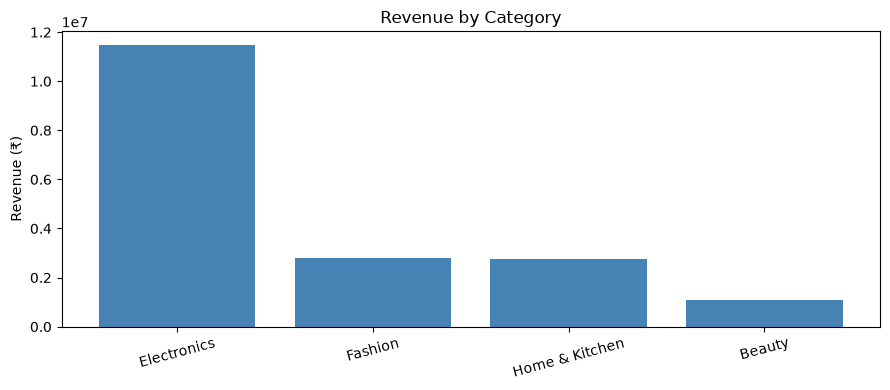

In [20]:
totals = df.groupby('Category')['Revenue'].sum().sort_values(ascending=False)
plt.figure(figsize=(9, 4))
plt.bar(totals.index, totals.values, color='steelblue')
plt.title('Revenue by Category'); plt.ylabel('Revenue (₹)')
plt.xticks(rotation=15); plt.tight_layout(); plt.show()

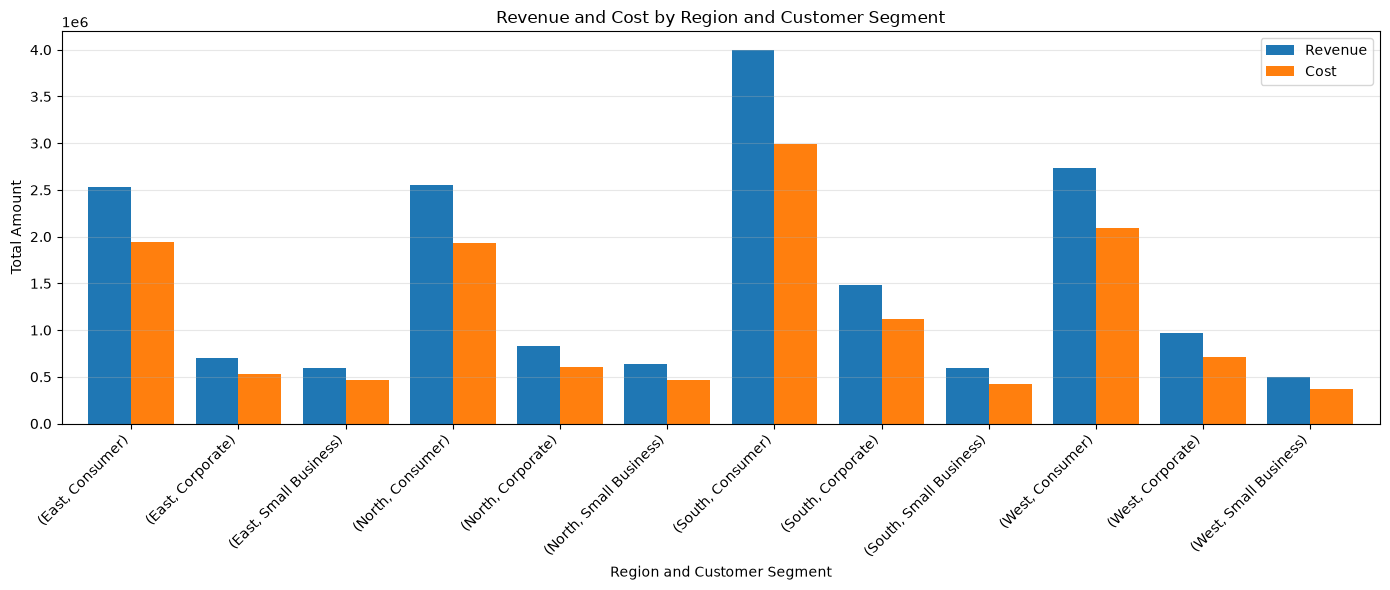

In [24]:
total = df.groupby(['Region','Customer_Segment'])[['Revenue', 'Cost']].sum()
total.plot(kind='bar', figsize=(14, 6), width=0.8)

plt.title('Revenue and Cost by Region and Customer Segment')
plt.xlabel('Region and Customer Segment')
plt.ylabel('Total Amount')
plt.xticks(rotation=45, ha='right')
plt.legend(['Revenue', 'Cost'])
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()
